# Construction Site PPE Detection with YOLOv8

**Objective:** fine-tune a pretrained YOLOv8 model to detect personal protective equipment (PPE) and site objects in images.

- **Dataset:** Construction Site Safety (Roboflow, exported in YOLO format, hosted on Kaggle). Classes include Hardhat, NO-Hardhat, Mask, NO-Mask, Safety Vest, NO-Safety Vest, Person, Safety Cone, machinery and vehicle.
- **Model:** `yolov8n.pt` (COCO pretrained), fine-tuned for 30 epochs.
- **Framework:** Ultralytics.

**Runtime:** use a GPU (Colab: Runtime > Change runtime type > T4 GPU).

## 1. Environment setup

In [2]:
!pip install -q ultralytics kagglehub
import ultralytics
ultralytics.checks()

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [3]:
import glob, os, shutil, yaml
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from ultralytics import YOLO

## 2. Download the dataset

In [5]:
path = kagglehub.dataset_download("snehilsanyal/construction-site-safety-image-dataset-roboflow")
print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'construction-site-safety-image-dataset-roboflow' dataset.
Dataset downloaded to: /kaggle/input/construction-site-safety-image-dataset-roboflow


In [6]:
# Check the downloaded dataset
from pathlib import Path

dataset_path = Path(path)

print("Dataset path:", dataset_path)
print("Does it exist?", dataset_path.exists())

print("\nFiles and folders in the dataset:")
for item in list(dataset_path.iterdir())[:30]:
    print(item.name)

print("\nYAML files found:")
yaml_files = list(dataset_path.rglob("*.yaml")) + list(dataset_path.rglob("*.yml"))

for file in yaml_files:
    print(file)

Dataset path: /kaggle/input/construction-site-safety-image-dataset-roboflow
Does it exist? True

Files and folders in the dataset:
css-data
source_files
results_yolov8n_100e

YAML files found:
/kaggle/input/construction-site-safety-image-dataset-roboflow/results_yolov8n_100e/kaggle/working/ppe_data.yaml
/kaggle/input/construction-site-safety-image-dataset-roboflow/results_yolov8n_100e/kaggle/working/runs/detect/train/args.yaml


The dataset is already in YOLO format. The cell below locates `data.yaml`, resolves the train / valid / test folders, and writes a clean `data.yaml` with absolute paths so Ultralytics can read it from any location.

In [7]:

from pathlib import Path

dataset_root = Path(path)

print("Dataset exists:", dataset_root.exists())
print("Dataset location:", dataset_root)

print("\nDataset folders and files:")

for item in sorted(dataset_root.rglob("*")):
    relative = item.relative_to(dataset_root)

    if len(relative.parts) <= 3:
        if item.is_dir():
            print("FOLDER:", relative)
        else:
            print("FILE:", relative)


Dataset exists: True
Dataset location: /kaggle/input/construction-site-safety-image-dataset-roboflow

Dataset folders and files:
FOLDER: css-data
FILE: css-data/README.dataset.txt
FILE: css-data/README.roboflow.txt
FOLDER: css-data/test
FOLDER: css-data/test/images
FOLDER: css-data/test/labels
FOLDER: css-data/train
FOLDER: css-data/train/images
FOLDER: css-data/train/labels
FOLDER: css-data/valid
FOLDER: css-data/valid/images
FOLDER: css-data/valid/labels
FOLDER: results_yolov8n_100e
FOLDER: results_yolov8n_100e/kaggle
FOLDER: results_yolov8n_100e/kaggle/working
FOLDER: source_files
FOLDER: source_files/source_files
FILE: source_files/source_files/JapanPPE.mp4
FILE: source_files/source_files/construction-safety.jpg
FILE: source_files/source_files/download.jfif
FILE: source_files/source_files/hardhat.mp4
FILE: source_files/source_files/images.jfif
FILE: source_files/source_files/indianworkers.mp4
FILE: source_files/source_files/portrait-of-woman-with-mask-and-man-with-safety-glasses-on

In [8]:
# Check whether a YAML file exists


yaml_files = (
    list(dataset_root.rglob("*.yaml")) +
    list(dataset_root.rglob("*.yml"))
)

print("YAML files found:", len(yaml_files))

for file in yaml_files:
    print(file)


YAML files found: 2
/kaggle/input/construction-site-safety-image-dataset-roboflow/results_yolov8n_100e/kaggle/working/ppe_data.yaml
/kaggle/input/construction-site-safety-image-dataset-roboflow/results_yolov8n_100e/kaggle/working/runs/detect/train/args.yaml


In [9]:

import yaml
from pathlib import Path

existing_yaml = Path(yaml_files[0])

print("YAML file:", existing_yaml)

with open(existing_yaml, "r") as f:
    old_cfg = yaml.safe_load(f)

print("\nExisting YAML content:")
print(yaml.dump(old_cfg, sort_keys=False))


YAML file: /kaggle/input/construction-site-safety-image-dataset-roboflow/results_yolov8n_100e/kaggle/working/ppe_data.yaml

Existing YAML content:
names:
- Hardhat
- Mask
- NO-Hardhat
- NO-Mask
- NO-Safety Vest
- Person
- Safety Cone
- Safety Vest
- machinery
- vehicle
nc: 10
test: /kaggle/input/construction-site-safety-image-dataset-roboflow/test
train: /kaggle/input/construction-site-safety-image-dataset-roboflow/train
val: /kaggle/input/construction-site-safety-image-dataset-roboflow/valid



In [10]:

dataset_info = dataset_root / "css-data"

print("Dataset README information:\n")

for filename in ["README.dataset.txt", "README.roboflow.txt"]:
    file_path = dataset_info / filename

    if file_path.exists():
        print(f"\n--- {filename} ---")
        print(file_path.read_text())



Dataset README information:


--- README.dataset.txt ---
# Construction Site Safety > YOLOv5s
https://universe.roboflow.com/roboflow-universe-projects/construction-site-safety

Provided by a Roboflow user
License: CC BY 4.0

videos from:
* https://www.youtube.com/watch?v=Dhxf5mm7g1g
* https://www.youtube.com/watch?v=rYv9JZ2XBW4

images cloned from:
* https://universe.roboflow.com/roboflow-universe-projects/personal-protective-equipment-combined-model/
* https://universe.roboflow.com/roboflow-universe-projects/people-and-ladders/
* https://universe.roboflow.com/roboflow-universe-projects/safety-vests/
* https://universe.roboflow.com/mohamed-sabek-6zmr6/excavators-cwlh0
* https://universe.roboflow.com/popular-benchmarks/mit-indoor-scene-recognition/ - null images
* https://universe.roboflow.com/mohamed-traore-2ekkp/people-detection-general
* https://universe.roboflow.com/labeler-projects/construction-madness/

--- README.roboflow.txt ---

Construction Site Safety - v28 YOLOv5s

This data

In [11]:

from pathlib import Path

for split in ["train", "valid", "test"]:

    images_dir = dataset_info / split / "images"
    labels_dir = dataset_info / split / "labels"

    images = list(images_dir.glob("*"))
    labels = list(labels_dir.glob("*.txt"))

    print(f"\n{split.upper()} DATA")
    print("Images:", len(images))
    print("Label files:", len(labels))



TRAIN DATA
Images: 2605
Label files: 2605

VALID DATA
Images: 114
Label files: 114

TEST DATA
Images: 82
Label files: 82


In [12]:
import yaml
from pathlib import Path

# Actual dataset folder
dataset_info = Path(path) / "css-data"

# Class names from the existing dataset YAML
names = [
    "Hardhat",
    "Mask",
    "NO-Hardhat",
    "NO-Mask",
    "NO-Safety Vest",
    "Person",
    "Safety Cone",
    "Safety Vest",
    "machinery",
    "vehicle"
]

# Create the correct dataset configuration
data_cfg = {
    "path": str(dataset_info),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 10,
    "names": names
}

# Save the YAML file
DATA_YAML = "/content/ppe_data.yaml"

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)

print("Dataset YAML created successfully!")
print(Path(DATA_YAML).read_text())

Dataset YAML created successfully!
path: /kaggle/input/construction-site-safety-image-dataset-roboflow/css-data
train: train/images
val: valid/images
test: test/images
nc: 10
names:
- Hardhat
- Mask
- NO-Hardhat
- NO-Mask
- NO-Safety Vest
- Person
- Safety Cone
- Safety Vest
- machinery
- vehicle



In [13]:
# verify ymal path

for split in ["train", "valid", "test"]:
    folder = dataset_info / split / "images"

    print(split.upper(), "exists:", folder.exists())

TRAIN exists: True
VALID exists: True
TEST exists: True


## 3. Dataset overview

In [14]:
# Define dataset folders
train_dir = str(dataset_info / "train" / "images")
val_dir = str(dataset_info / "valid" / "images")
test_dir = str(dataset_info / "test" / "images")

# Count images
def count_images(folder):
    return len(list(Path(folder).glob("*")))

# Display dataset information
print(f"Train images : {count_images(train_dir)}")
print(f"Valid images : {count_images(val_dir)}")
print(f"Test images  : {count_images(test_dir)}")

print(f"\nClasses ({len(names)}): {names}")

Train images : 2605
Valid images : 114
Test images  : 82

Classes (10): ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle']


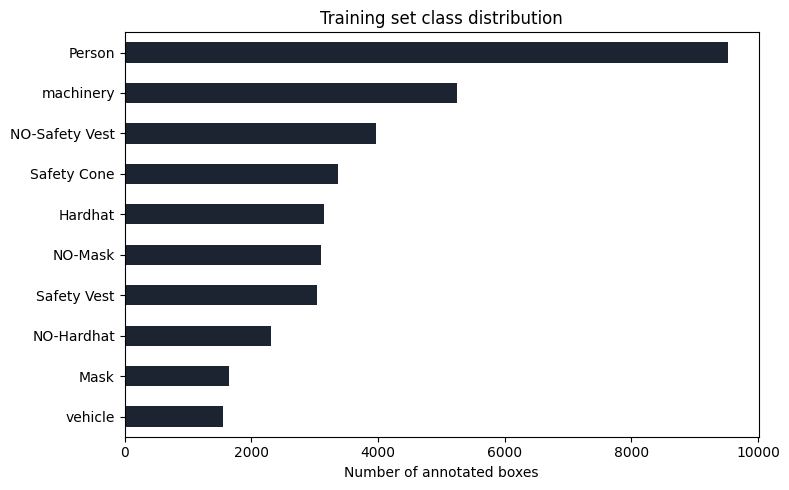

In [15]:
# Class distribution in the training labels
from collections import Counter
counter = Counter()
label_dir = Path(train_dir).parent / "labels"
for lf in label_dir.glob("*.txt"):
    for line in lf.read_text().splitlines():
        if line.strip():
            counter[int(line.split()[0])] += 1

dist = pd.Series({names[k]: v for k, v in sorted(counter.items())})
ax = dist.sort_values().plot(kind="barh", figsize=(8, 5), color="#1B2430")
ax.set_xlabel("Number of annotated boxes")
ax.set_title("Training set class distribution")
plt.tight_layout(); plt.show()

## 4. Train the model

Fine-tuning `yolov8n.pt` for 30 epochs at 640 px. The full per-epoch log (losses, precision, recall, mAP50, mAP50-95) is printed below.

In [16]:
model = YOLO("yolov8n.pt")

results = model.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=640,
    batch=16,
    patience=15,
    optimizer="auto",
    seed=42,
    project="runs",
    name="ppe_yolov8n",
    exist_ok=True,
    plots=True,
    verbose=True,
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ppe_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ppe_yolov8n, nbs=64, nms=None, opset=None, optimize=False, optimize

## 5. Evaluate the model

In [18]:
best_path = "/content/runs/detect/runs/ppe_yolov8n/weights/best.pt"
best = YOLO(best_path)
metrics = best.val(data=DATA_YAML, split="val", imgsz=640)

print("\n==== Final validation metrics ====")
print(f"mAP50     : {metrics.box.map50:.4f}")
print(f"mAP50-95  : {metrics.box.map:.4f}")
print(f"Precision : {metrics.box.mp:.4f}")
print(f"Recall    : {metrics.box.mr:.4f}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.5 ms, read: 159.8±67.8 MB/s, size: 61.4 KB)
val: Scanning /kaggle/input/construction-site-safety-image-dataset-roboflow/css-data/valid/labels... 114 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 114/114 435.9it/s 0.3s
WARNING ⚠️ val: Cache directory /kaggle/input/construction-site-safety-image-dataset-roboflow/css-data/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.0it/s 2.6s
                   all        114        697      0.898      0.658      0.763      0.443
               Hardhat         42         79      0.933        0.7      0.825      0.527
                  Mask         19         21      0.945       0.81      0.888      0.621
            NO-Hardhat         37     

In [19]:
# Per-class AP50
per_class = pd.DataFrame({
    "Class": [names[i] for i in metrics.box.ap_class_index],
    "AP50": metrics.box.ap50,
    "AP50-95": metrics.box.ap,
}).sort_values("AP50", ascending=False).reset_index(drop=True)
per_class

,Class,AP50,AP50-95
0,machinery,0.918789,0.535335
1,Mask,0.888000,0.621183
2,Safety Vest,0.874473,0.541068
3,Safety Cone,0.861395,0.460723
4,Hardhat,0.824734,0.527009
5,Person,0.810860,0.474367
6,NO-Safety Vest,0.744415,0.401820
7,NO-Hardhat,0.634211,0.315519
8,NO-Mask,0.569260,0.264358
9,vehicle,0.507477,0.290551


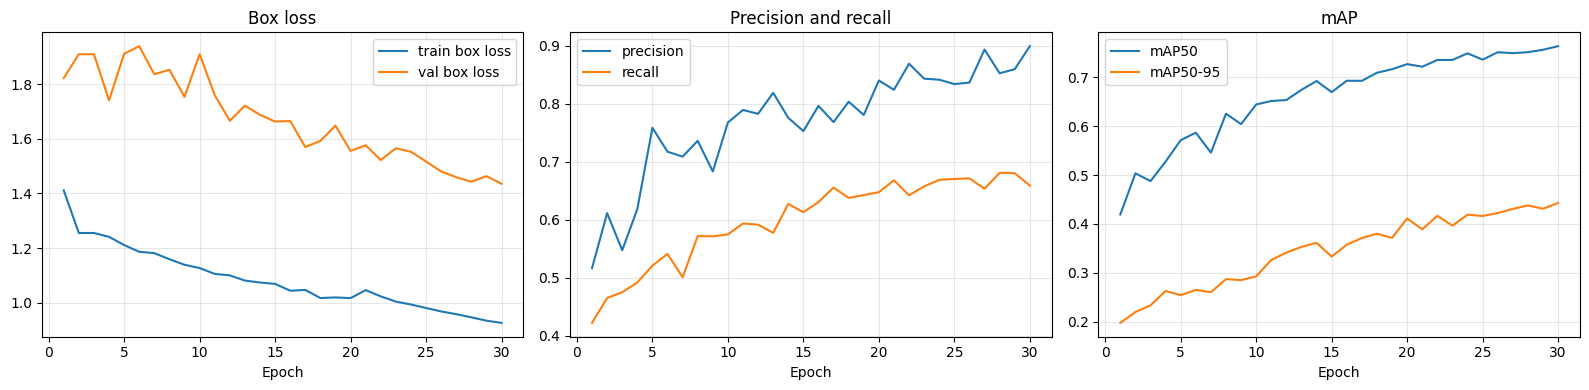

In [21]:
# Training curves
res = pd.read_csv("/content/runs/detect/runs/ppe_yolov8n/results.csv")
res.columns = [c.strip() for c in res.columns]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(res["epoch"], res["train/box_loss"], label="train box loss")
axes[0].plot(res["epoch"], res["val/box_loss"], label="val box loss")
axes[0].set_title("Box loss"); axes[0].legend()
axes[1].plot(res["epoch"], res["metrics/precision(B)"], label="precision")
axes[1].plot(res["epoch"], res["metrics/recall(B)"], label="recall")
axes[1].set_title("Precision and recall"); axes[1].legend()
axes[2].plot(res["epoch"], res["metrics/mAP50(B)"], label="mAP50")
axes[2].plot(res["epoch"], res["metrics/mAP50-95(B)"], label="mAP50-95")
axes[2].set_title("mAP"); axes[2].legend()
for a in axes: a.set_xlabel("Epoch"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [22]:
# Confusion matrix and PR curve produced by Ultralytics
for f in ["confusion_matrix_normalized.png", "PR_curve.png"]:
    p = f"runs/ppe_yolov8n/{f}"
    if os.path.exists(p):
        plt.figure(figsize=(9, 7)); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.title(f); plt.show()

## 6. Sample predictions on validation images

Results saved to /content/runs/detect/runs/samples


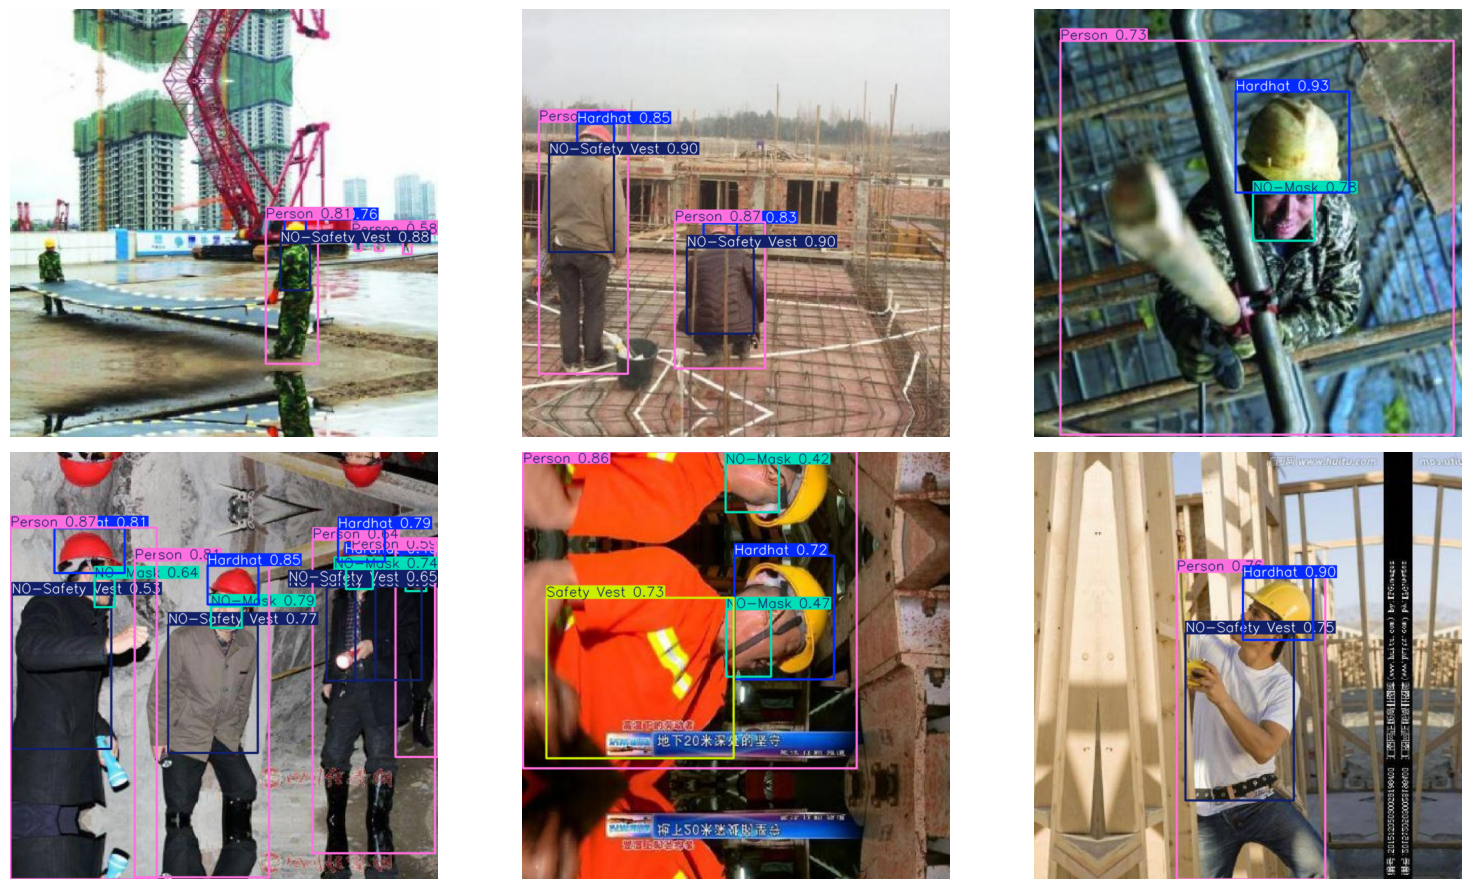

In [23]:
val_imgs = sorted(glob.glob(os.path.join(val_dir, "*")))[:6]
preds = best.predict(val_imgs, conf=0.4, imgsz=640, save=True, project="runs", name="samples", exist_ok=True, verbose=False)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, r in zip(axes.ravel(), preds):
    ax.imshow(r.plot()[..., ::-1]); ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Export the trained weights

Download `best.pt` and place it in the app repository at `models/best.pt`.

In [25]:
os.makedirs("export", exist_ok=True)
shutil.copy(best_path, "export/best.pt")
print("Weights size: %.1f MB" % (os.path.getsize("export/best.pt") / 1e6))

try:
    from google.colab import files
    files.download("export/best.pt")
    shutil.make_archive("export/training_results", "zip", "/content/runs/detect/runs/ppe_yolov8n")
    files.download("export/training_results.zip")
except ImportError:
    print("Not running in Colab. Copy export/best.pt manually.")

Weights size: 6.5 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>